In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

p = np.load("../results/test_preds_calibrated.npy")
meta = pd.read_csv("../results/test_meta.csv")
y = meta["target"].values

print(f"Test flights: {len(y):,}")
print(f"Actual delay rate: {y.mean():.1%}")
print(f"Mean predicted:    {p.mean():.1%}")

COST_DELAY      = 1500    
COST_ACTION     = 200    
MITIGATION_RATE = 0.40  

Test flights: 1,197,046
Actual delay rate: 25.9%
Mean predicted:    24.8%


In [2]:
rows = []
for t in np.arange(0.05, 0.95, 0.01):
    flag = p >= t
    tn, fp, fn, tp = confusion_matrix(y, flag, labels=[0,1]).ravel()

    cost_no_model = (tp + fn) * COST_DELAY
    cost_model = ((tp + fp) * COST_ACTION
                  + tp * COST_DELAY * (1 - MITIGATION_RATE)
                  + fn * COST_DELAY)

    rows.append({
        "threshold": round(t, 2),
        "flagged": int(flag.sum()),
        "flagged_pct": flag.mean(),
        "precision": tp / (tp + fp) if (tp + fp) else 0.0,
        "recall": tp / (tp + fn),
        "savings": cost_no_model - cost_model,
    })

bt = pd.DataFrame(rows)
best = bt.loc[bt["savings"].idxmax()]

print(f"Optimal threshold: {best['threshold']:.2f}")
print(f"  Flags {best['flagged']:,} flights ({best['flagged_pct']:.1%})")
print(f"  Precision {best['precision']:.1%}, recall {best['recall']:.1%}")
print(f"  Estimated savings: ${best['savings']:,.0f}")
print(f"  Per 1,000 flights: ${best['savings']/len(y)*1000:,.0f}")

Optimal threshold: 0.30
  Flags 238,952.0 flights (20.0%)
  Precision 71.2%, recall 54.8%
  Estimated savings: $54,311,000
  Per 1,000 flights: $45,371


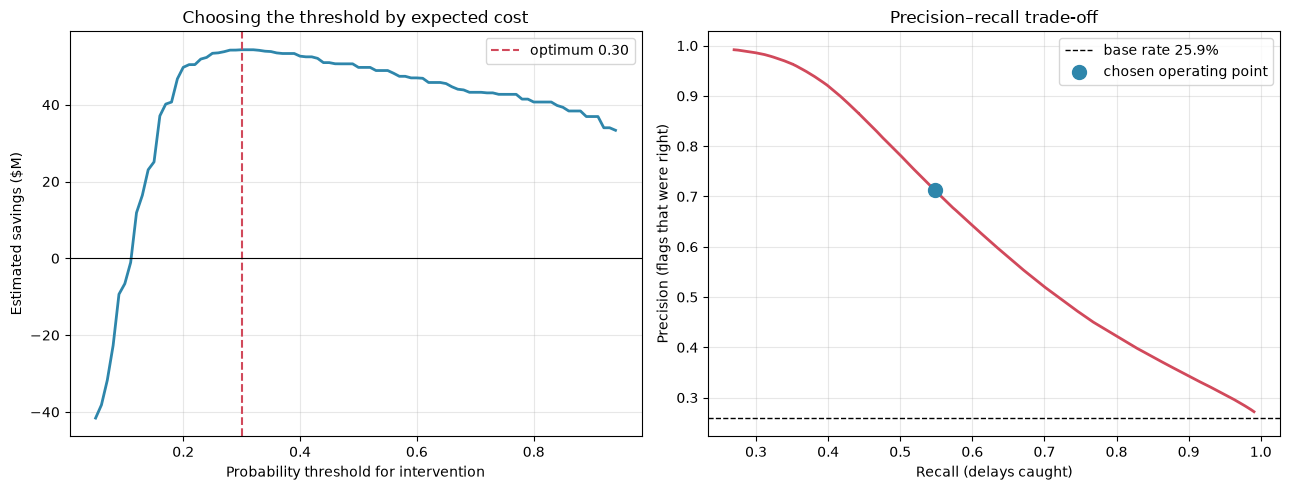

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ax[0].plot(bt["threshold"], bt["savings"]/1e6, color="#2e86ab", lw=2)
ax[0].axvline(best["threshold"], ls="--", c="#d1495b",
              label=f"optimum {best['threshold']:.2f}")
ax[0].axhline(0, c="k", lw=0.8)
ax[0].set_xlabel("Probability threshold for intervention")
ax[0].set_ylabel("Estimated savings ($M)")
ax[0].set_title("Choosing the threshold by expected cost")
ax[0].legend(); ax[0].grid(alpha=.3)

ax[1].plot(bt["recall"], bt["precision"], color="#d1495b", lw=2)
ax[1].axhline(y.mean(), ls="--", c="k", lw=1, label=f"base rate {y.mean():.1%}")
opt = bt.loc[bt["savings"].idxmax()]
ax[1].scatter([opt["recall"]], [opt["precision"]], s=100, c="#2e86ab",
              zorder=5, label="chosen operating point")
ax[1].set_xlabel("Recall (delays caught)")
ax[1].set_ylabel("Precision (flags that were right)")
ax[1].set_title("Precision–recall trade-off")
ax[1].legend(); ax[1].grid(alpha=.3)

plt.tight_layout()
plt.savefig("../figures/04_threshold.png", dpi=200)
plt.show()

In [4]:
sens = []
for mit in [0.2, 0.3, 0.4, 0.5, 0.6]:
    for cost in [750, 1500, 3000]:
        best_t, best_s = 0, -np.inf
        for t in np.arange(0.05, 0.95, 0.02):
            flag = p >= t
            tn, fp, fn, tp = confusion_matrix(y, flag, labels=[0,1]).ravel()
            s = (tp+fn)*cost - ((tp+fp)*COST_ACTION + tp*cost*(1-mit) + fn*cost)
            if s > best_s:
                best_t, best_s = t, s
        sens.append({"mitigation": mit, "delay_cost": cost,
                     "best_threshold": round(best_t, 2),
                     "savings_per_1k": round(best_s/len(y)*1000)})

sens_df = pd.DataFrame(sens)
print("Optimal threshold under different assumptions:")
print(sens_df.pivot(index="mitigation", columns="delay_cost",
                    values="best_threshold").to_string())
print("\nSavings per 1,000 flights:")
print(sens_df.pivot(index="mitigation", columns="delay_cost",
                    values="savings_per_1k").to_string())

Optimal threshold under different assumptions:
delay_cost  750   1500  3000
mitigation                  
0.2         0.93  0.63  0.31
0.3         0.87  0.43  0.21
0.4         0.63  0.31  0.17
0.5         0.51  0.25  0.13
0.6         0.43  0.21  0.11

Savings per 1,000 flights:
delay_cost   750    1500    3000
mitigation                      
0.2         -3695   8589   45369
0.3          1728  25316   93715
0.4          8589  45369  150238
0.5         16534  68397  215078
0.6         25316  93715  284134


In [5]:
meta["pred"] = p
meta["flagged"] = p >= best["threshold"]

print("By carrier:")
print(meta.groupby("carrier").agg(
    flights=("target", "size"),
    actual_rate=("target", "mean"),
    flagged_rate=("flagged", "mean"),
).round(3).sort_values("flagged_rate", ascending=False).to_string())

print("\nBy first-leg status:")
print(meta.groupby("is_first_leg").agg(
    flights=("target", "size"),
    actual_rate=("target", "mean"),
    flagged_rate=("flagged", "mean"),
).round(3).to_string())

By carrier:
         flights  actual_rate  flagged_rate
carrier                                    
F9         31358        0.345         0.305
OH         40695        0.337         0.292
AA        167479        0.296         0.252
G4         24716        0.276         0.233
MQ         51167        0.242         0.211
WN        240036        0.256         0.209
AS         43953        0.278         0.185
B6         38191        0.270         0.179
OO        144871        0.219         0.173
NK         34810        0.250         0.171
DL        178627        0.241         0.170
UA        132587        0.254         0.163
YX         54777        0.251         0.157
HA         13779        0.152         0.134

By first-leg status:
              flights  actual_rate  flagged_rate
is_first_leg                                    
0              904691        0.295         0.240
1              292355        0.147         0.074


In [6]:
rules = {
    "Model (optimal threshold)": p >= best["threshold"],
    "Rule: flag all afternoon/evening (dep_hour >= 15)": meta["dep_hour"].values >= 15,
    "Rule: flag all non-first legs": meta["is_first_leg"].values == 0,
    "Rule: flag everything": np.ones(len(y), dtype=bool),
}

out = []
for name, flag in rules.items():
    tn, fp, fn, tp = confusion_matrix(y, flag, labels=[0,1]).ravel()
    s = (tp+fn)*COST_DELAY - ((tp+fp)*COST_ACTION + tp*COST_DELAY*(1-MITIGATION_RATE) + fn*COST_DELAY)
    out.append({"strategy": name, "flagged_pct": flag.mean(),
                "precision": tp/(tp+fp) if (tp+fp) else 0,
                "recall": tp/(tp+fn),
                "savings_per_1k": round(s/len(y)*1000)})
print(pd.DataFrame(out).round(3).to_string(index=False))

                                         strategy  flagged_pct  precision  recall  savings_per_1k
                        Model (optimal threshold)        0.200      0.712   0.548           45371
Rule: flag all afternoon/evening (dep_hour >= 15)        0.405      0.373   0.583            9624
                    Rule: flag all non-first legs        0.756      0.295   0.861          -17157
                            Rule: flag everything        1.000      0.259   1.000          -44395


In [7]:
bt.to_csv("../results/threshold_sweep.csv", index=False)
sens_df.to_csv("../results/sensitivity.csv", index=False)
with open("../results/chosen_threshold.txt", "w") as f:
    f.write(str(best["threshold"]))
print("Saved")

Saved


In [9]:
import duckdb, pandas as pd, pickle, json

con = duckdb.connect("../data/processed/flights.duckdb")

route = con.execute("SELECT * FROM route_hist").df()
carrier = con.execute("SELECT * FROM carrier_hist").df()
airport = con.execute("SELECT * FROM airport_hist").df()
airport_hour = con.execute("SELECT * FROM airport_hour_hist").df()
con.close()

lookups = {
    "route": {f"{r.Origin}-{r.Dest}": [r.route_delay_rate, r.route_mean_delay]
              for r in route.itertuples()},
    "carrier": dict(zip(carrier["carrier"], carrier["carrier_delay_rate"])),
    "airport": {r.airport: [r.origin_delay_rate, r.avg_daily_departures]
                for r in airport.itertuples()},
    "airport_hour": {f"{r.airport}-{int(r.hour)}": [r.departures_this_hour, r.hour_delay_rate]
                     for r in airport_hour.itertuples()},
    "carriers": sorted(carrier["carrier"].tolist()),
    "airports": sorted(airport["airport"].tolist()),
}

with open("../results/lookups.json", "w") as f:
    json.dump(lookups, f)

import os
print(f"lookups.json: {os.path.getsize('../results/lookups.json')/1e6:.1f} MB")
print(f"model.pkl: {os.path.getsize('../results/model.pkl')/1e6:.1f} MB")

lookups.json: 0.4 MB
model.pkl: 7.1 MB
